# Mouse embryogenesis atlas

This tutorial jointly models eight MOSTA Stereo-seq stages from E9.5 to E16.5.
We summarize temporal deployment across all GEPs and visualize neural,
epithelial, chondrogenic and contractile programs. Use one section per stage
for this example. Download the stage H5AD files
from the [MOSTA download page](https://db.cngb.org/stomics/mosta/download/), combine them
by an outer join over genes and save the input as
`data/embryogenesis/embryogenesis_counts.h5ad` under the tutorial repository root.
Use a common gene column order and a sparse count matrix, filling genes absent
from a stage with zeros. Keep coordinates and metadata aligned by row.

Store counts in `adata.X`, gene symbols in `var_names` and original spatial
coordinates in `obsm['spatial']`. In `obs`, `slice_id` identifies stages
(`E9.5` through `E16.5`) and `annotation` contains the atlas anatomical labels.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse

import sort


stages = ["E9.5", "E10.5", "E11.5", "E12.5", "E13.5", "E14.5", "E15.5", "E16.5"]

## 1. Load and preprocess the atlas

Load the outer-joined count atlas. Each location retains its developmental
stage, anatomical annotation and original spatial coordinates.

In [3]:
adata = sc.read_h5ad(Path("../data/embryogenesis/embryogenesis_counts.h5ad"))
adata

AnnData object with n_obs × n_vars = 520815 × 29678
    obs: 'annotation', 'slice_id'
    uns: 'tutorial_provenance'
    obsm: 'spatial'

Retain locations with at least 50
detected genes, keep genes detected in at least 0.1% of retained locations,
normalize and log-transform, and select 8,000 stage-aware highly variable
genes.

In [4]:
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=None)
adata = adata[adata.obs["n_genes_by_counts"] >= 50].copy()

min_cells = max(1, int(np.ceil(adata.n_obs * 0.001)))
detected_per_gene = np.asarray((adata.X > 0).sum(axis=0)).ravel()
adata = adata[:, detected_per_gene >= min_cells].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=8_000,
    batch_key="slice_id",
    flavor="seurat_v3",
)
adata = adata[:, adata.var["highly_variable"]].copy()
adata.X = sparse.csr_matrix(adata.X, dtype=np.float32)
adata

scanpy/preprocessing/_highly_variable_genes.py:64: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(


AnnData object with n_obs × n_vars = 520389 × 8000
    obs: 'annotation', 'slice_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'tutorial_provenance', 'log1p', 'hvg'
    obsm: 'spatial'

## 2. Build the spatial graph and fit SORT

Construct an eight-neighbour graph independently within each developmental
stage, then combine the graphs using the atlas row indices.

In [5]:
sort.build_per_sample_graph(
    adata, n_neighbors=8, sample_key="slice_id"
)

Building spatial graphs for 8 samples (k=8)...


  [8/8] Processed
✓ Combined Laplacian: (520389, 520389), 4,683,501 non-zeros



AnnData object with n_obs × n_vars = 520389 × 8000
    obs: 'annotation', 'slice_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'tutorial_provenance', 'log1p', 'hvg', 'spatial_laplacian'
    obsm: 'spatial'

Next, fit SORT with one background and 59 signal components using the
embryogenesis spatial and sparsity weights. Initialization and optimization
settings use the package defaults.

In [6]:
result = sort.fit(
    adata,
    n_components=60,
    use_highly_variable=False,
    alpha=0.4,
    lambda_l1_W=0.4,
    lambda_l1_Q=800,
)
result

SORT: 520,389 locations x 8,000 genes; 60 components; device=cuda


Initializing activities and profiles...


  ⚠️  Insufficient GPU memory (free=25.09 GB, need≈49.96 GB). Falling back to CPU numpy for HALS.


Stage 1: orthogonal Procrustes updates (50 epochs)


  Stage 1: 10/50 epochs


...

  Stage 2: 80/100 epochs


  Stage 2: 90/100 epochs


  Stage 2: 100/100 epochs


Finished in 1813.8 s
Stored .obsm['X_sort'] (520389, 60) and .varm['sort_signatures'] (8000, 60)


SORTResult(W=(520389, 60) spots_x_components, Q=(8000, 60) genes_x_components, background_component=0, fit_time=1813.8s)

## 3. Inspect and select programs

Inspect the ten genes with the largest positive weights in each signal
profile, then select programs to follow across development. Combine these
gene profiles with the spatial maps and atlas annotations below.

In [7]:
top_positive_genes = pd.DataFrame([
    {
        "GEP": f"GEP{k:02d}",
        "Top positive genes": ", ".join(
            pd.Series(result.Q[:, k], index=result.gene_names)
            .loc[lambda weights: weights > 0].nlargest(10).index
        ),
    }
    for k in range(1, result.Q.shape[1])
]).set_index("GEP")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(top_positive_genes)

,Top positive genes
GEP,
GEP01,"Tubb3, Hba-x, Crabp2, Marcksl1, H2afv, Rpl35, Nes, Serf2, Ddah2, Rpl34"
GEP02,"Mapt, Rtn1, Stmn2, Tubb2b, Gap43, Ina, Dpysl3, Map2, Crmp1, Tubb2a"
GEP03,"Hbb-y, Mdk, Lrba, Nnat, Mif, Snrpb, Ppia, H2afz, Ybx1, Hspe1"
GEP04,"Afp, Alb, Mt1, Gpx1, Apoa2, Hbb-bt, Slc25a37, Hbb-bs, Hba-a2, Trf"
GEP05,"Col1a2, Postn, Col3a1, Sparc, Col5a2, Fstl1, Malat1, Col6a3, Col5a1, Col12a1"
GEP06,"Acta1, Myh3, Mylpf, Actc1, Myl1, Tnnt1, Tpm2, Tnnc2, Tnni1, Myl4"
GEP07,"Hbb-y, Gm19951, Jarid2, Cd44, Zc3h7a, Cmss1, Gm26561, Tmtc2, D130009I18Rik, Gm15564"
GEP08,"Hbb-bs, Hba-a1, Hbb-bt, Hba-a2, Tuba1a, Hbb-y, Col1a2, mt-Nd4, Nnat, Col3a1"
GEP09,"Hmgb2, Hbb-bs, Hmgb1, Hnrnpa3, Top2a, Hmgn2, H2afz, Mki67, Igfbp2, Nucks1"


Set the component index, program label and atlas annotation for each example.
The defaults use the example's component indices; update them for your fit.
Indices refer directly to columns of `result.W` and `result.Q`, with the
background component at index 0. The spatial maps help refine your selection.

In [8]:
examples = [
    (25, "Chondrogenic", "Cartilage"),
    (31, "Epithelial", "Epidermis"),
    (2, "Neural", "Brain"),
    (6, "Sarcomeric", "Muscle"),
    (43, "Smooth-contractile", "Smooth muscle"),
]
assert all(0 < gep < result.W.shape[1] for gep, _, _ in examples)

## 4. Summarize activity across developmental stages

Calculate mean activity within each stage to compare temporal patterns across
all signal GEPs. Scale each program to its highest stage mean and order the
heatmap rows by peak stage and temporal center of mass. Colors show each
program's relative activity across stages, with its maximum set to 1.
Bold GEP labels mark the five programs selected above.

In [9]:
stage_labels = adata.obs["slice_id"].astype(str).to_numpy()
stage_means = np.vstack([
    result.W[stage_labels == stage, 1:].mean(axis=0) for stage in stages
])
stage_means /= np.maximum(stage_means.max(axis=0, keepdims=True), 1e-12)
peak = stage_means.argmax(axis=0)
center = (stage_means * np.arange(len(stages))[:, None]).sum(axis=0) / np.maximum(
    stage_means.sum(axis=0), 1e-12
)
order = np.lexsort((center, peak))

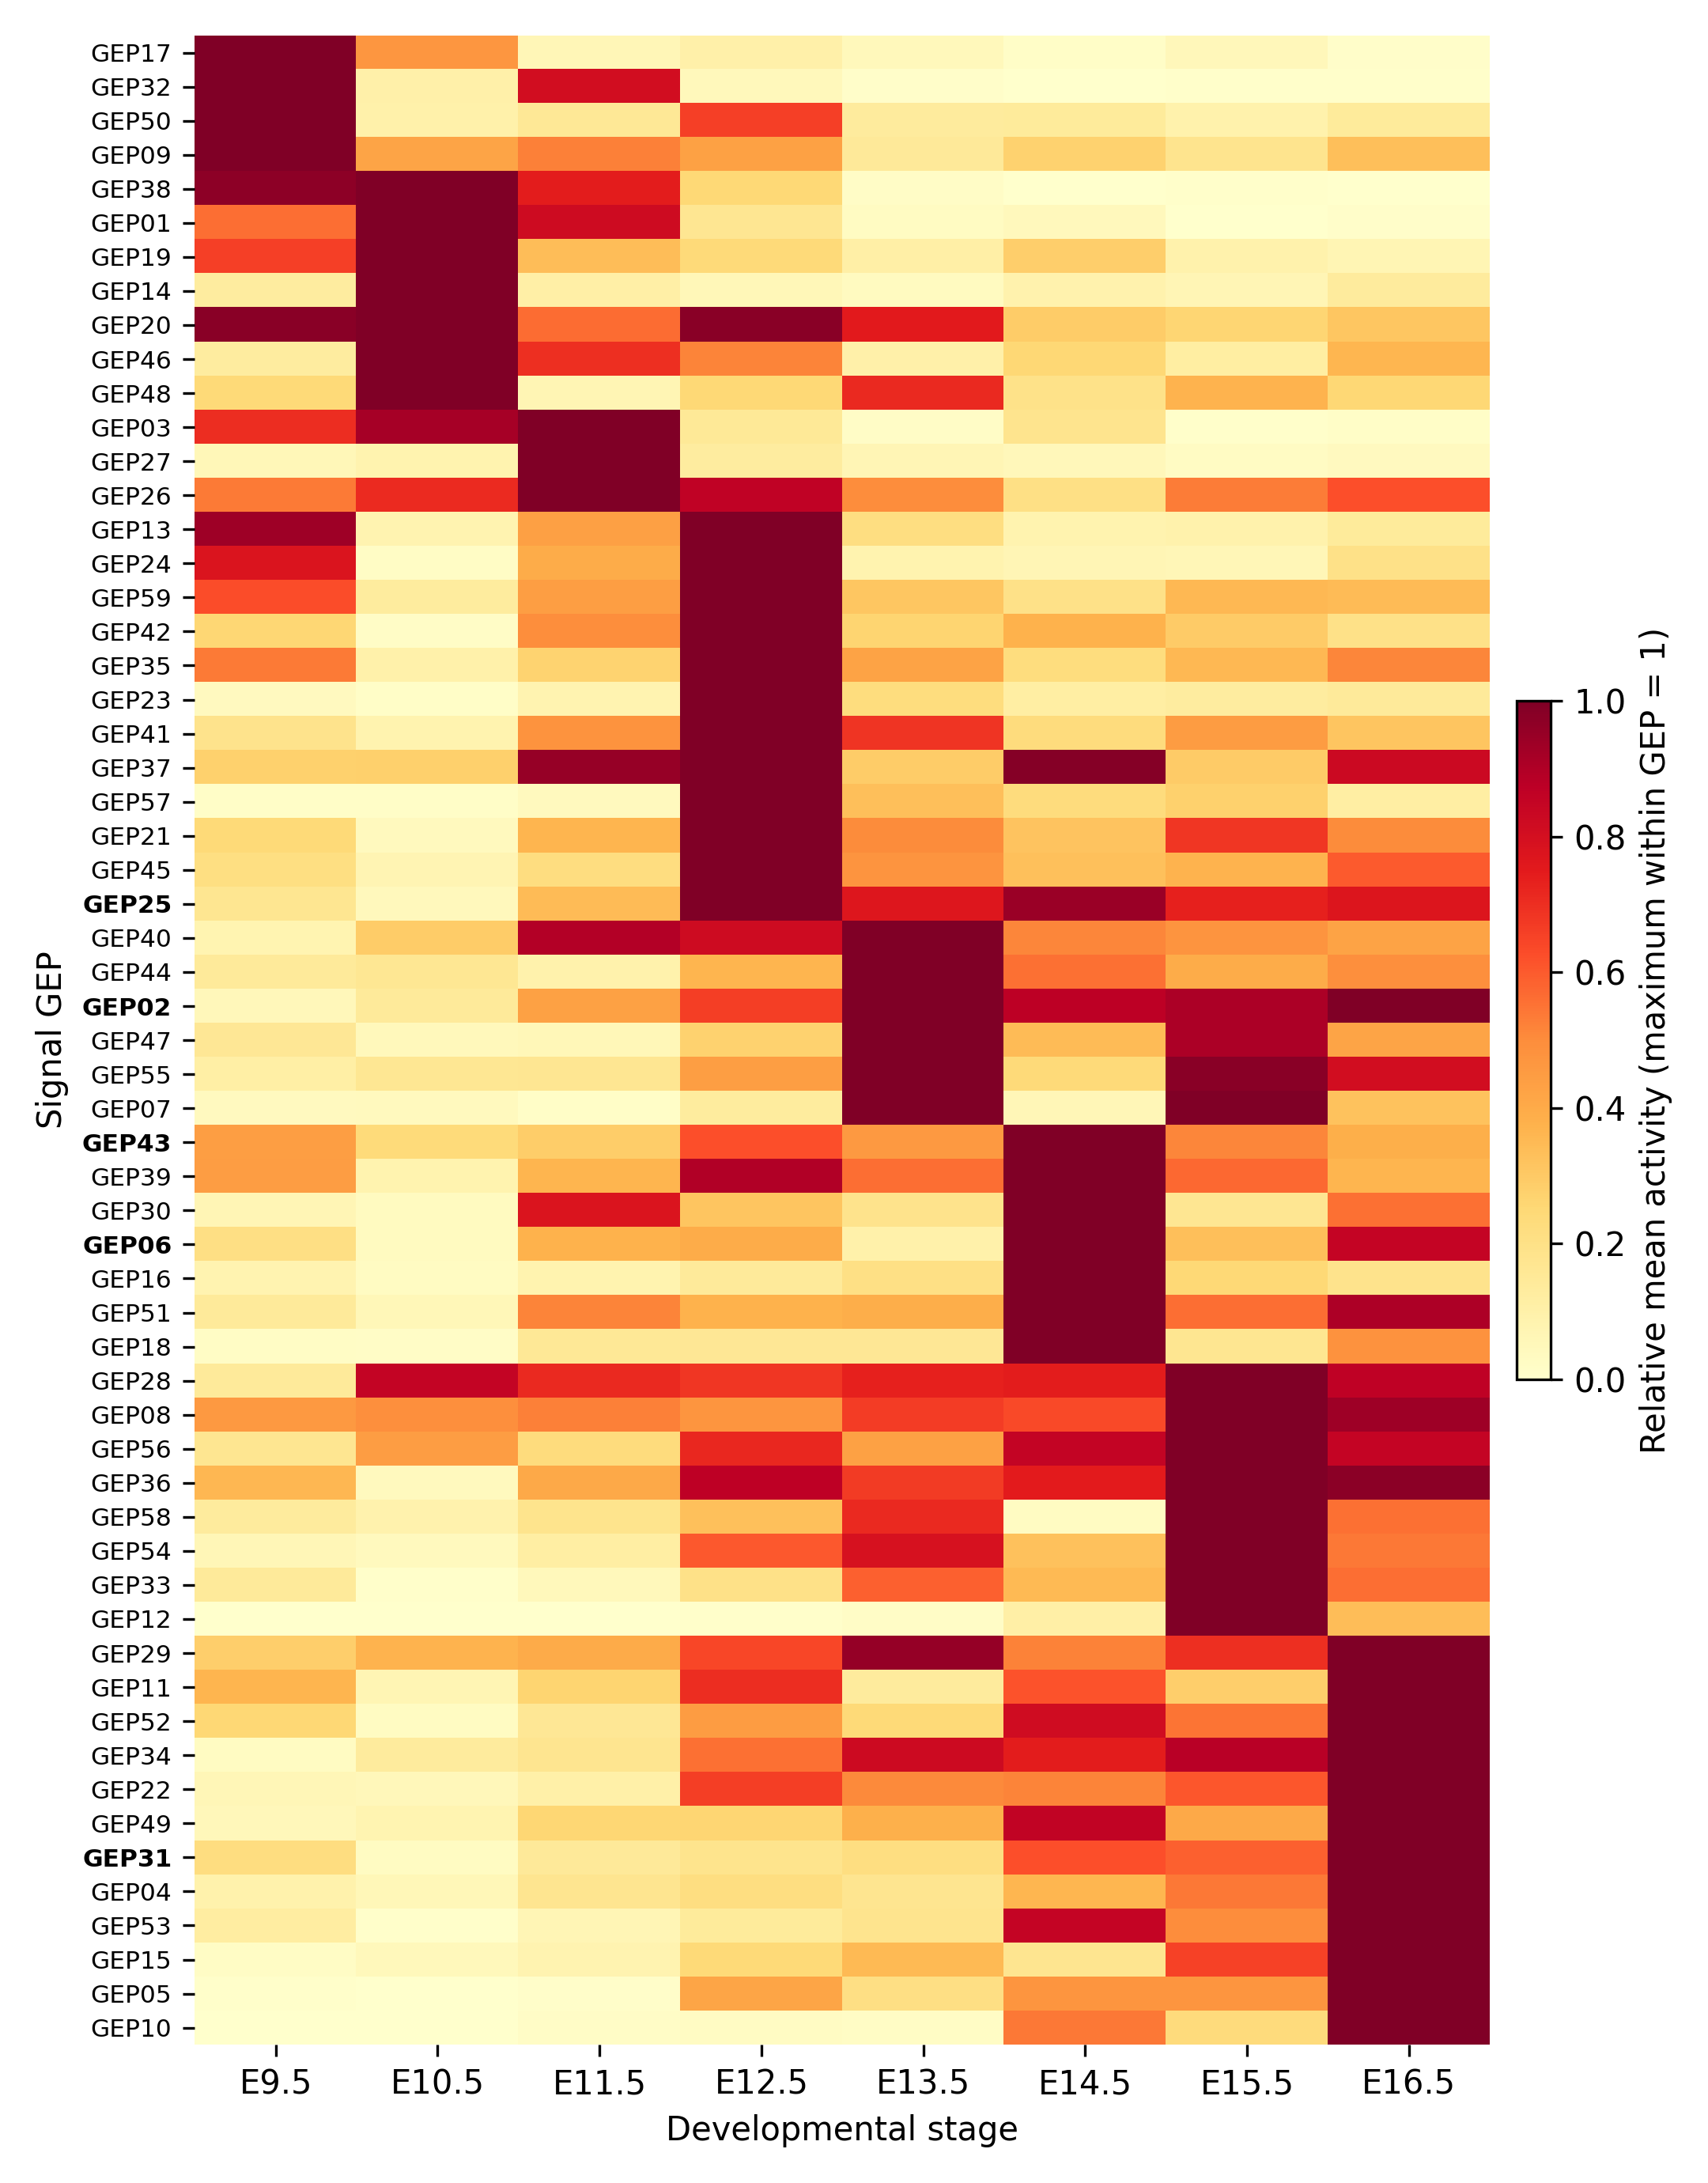

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 9.2))
image = ax.imshow(stage_means[:, order].T, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(stages)), stages)
ax.set_yticks(np.arange(len(order)), [f"GEP{i + 1:02d}" for i in order], fontsize=7.5)
selected_geps = {gep for gep, _, _ in examples}
for tick, component in zip(ax.get_yticklabels(), order + 1):
    if component in selected_geps:
        tick.set_fontweight("bold")
ax.set_xlabel("Developmental stage")
ax.set_ylabel("Signal GEP")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02,
             label="Relative mean activity (maximum within GEP = 1)")
fig.tight_layout()
plt.show()

## 5. Follow individual programs in space

Follow each selected program across all eight stages. The top row shows
SORT activity and the lower row highlights the atlas annotation specified in
`examples`. Use these maps to examine the program's spatial deployment.

In [11]:
coordinates = np.asarray(adata.obsm["spatial"], dtype=float)
annotations = adata.obs["annotation"].astype(str).to_numpy(dtype=str)

# Recenter each stage while retaining one common x/y scale. Smaller embryos
# therefore remain smaller instead of being stretched to fill each subplot.
stage_maps = {}
widths, heights = [], []
for stage in stages:
    mask = stage_labels == stage
    xy = coordinates[mask].copy()
    xy -= (xy.min(axis=0) + xy.max(axis=0)) / 2
    stage_maps[stage] = (mask, xy)
    widths.append(np.ptp(xy[:, 0]))
    heights.append(np.ptp(xy[:, 1]))
half_width = max(widths) * 0.53
half_height = max(heights) * 0.53


def plot_program(gep, label, annotation):
    positive = result.W[:, gep][result.W[:, gep] > 0]
    upper = np.quantile(positive, 0.995) if len(positive) else 1.0
    fig, axes = plt.subplots(2, len(stages), figsize=(14.0, 4.2))

    for column, stage in enumerate(stages):
        mask, xy = stage_maps[stage]
        activity = result.W[mask, gep]
        order = np.argsort(activity)
        axes[0, column].scatter(
            xy[order, 0], xy[order, 1], c=activity[order], s=0.08,
            cmap="Reds", vmin=0, vmax=upper, linewidths=0, rasterized=True,
        )

        selected = np.char.find(annotations[mask], annotation) >= 0
        axes[1, column].scatter(
            xy[:, 0], xy[:, 1], c="#E5E5E5", s=0.08,
            linewidths=0, rasterized=True,
        )
        axes[1, column].scatter(
            xy[selected, 0], xy[selected, 1], c="#4C78A8", s=0.10,
            linewidths=0, rasterized=True,
        )
        axes[0, column].set_title(stage, fontsize=8)

        for row in range(2):
            axes[row, column].set_xlim(-half_width, half_width)
            axes[row, column].set_ylim(half_height, -half_height)
            axes[row, column].set_aspect("equal", adjustable="box")
            axes[row, column].axis("off")

    fig.text(0.012, 0.64, "SORT activity", ha="left", va="center", fontsize=8)
    fig.text(0.012, 0.25, annotation, ha="left", va="center", fontsize=8)
    colorbar = fig.colorbar(
        axes[0, 0].collections[0], ax=axes[0], orientation="horizontal",
        fraction=0.035, pad=0.02, aspect=35,
    )
    colorbar.set_label("GEP activity", fontsize=8)
    colorbar.ax.tick_params(labelsize=7, length=2)
    fig.suptitle(f"GEP{gep:02d} — {label}", fontsize=10, y=0.99)
    fig.subplots_adjust(
        left=0.10, right=0.995, bottom=0.10, top=0.89,
        wspace=0.01, hspace=0.02,
    )
    plt.show()

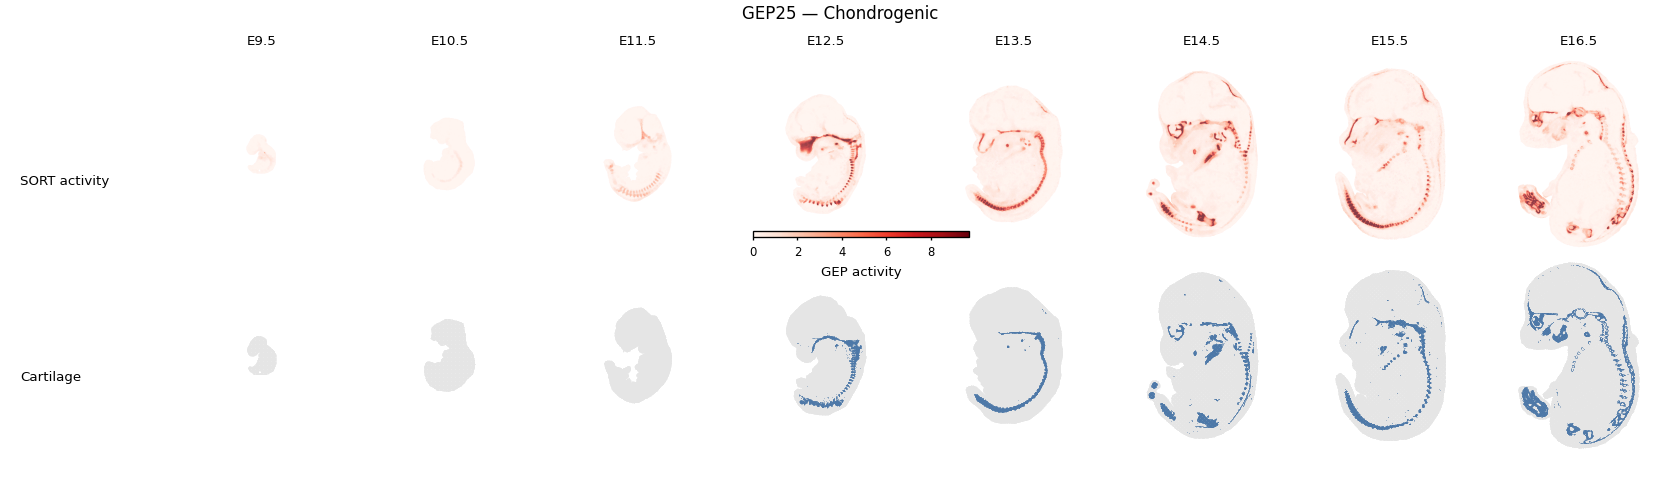

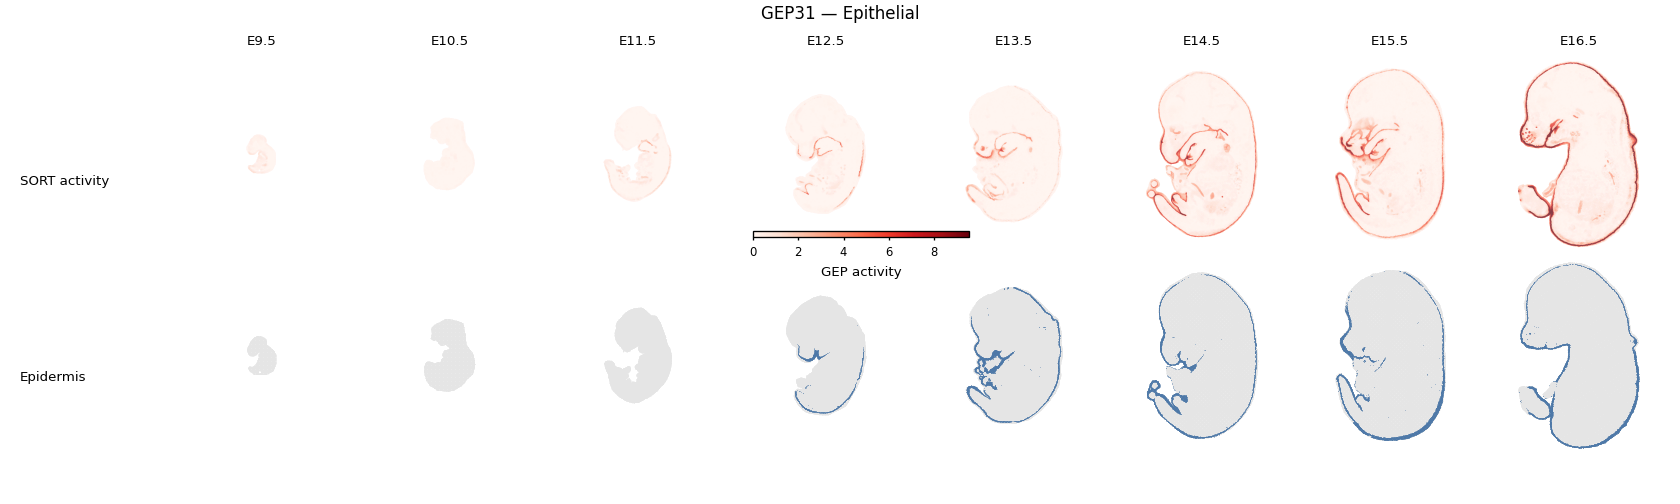

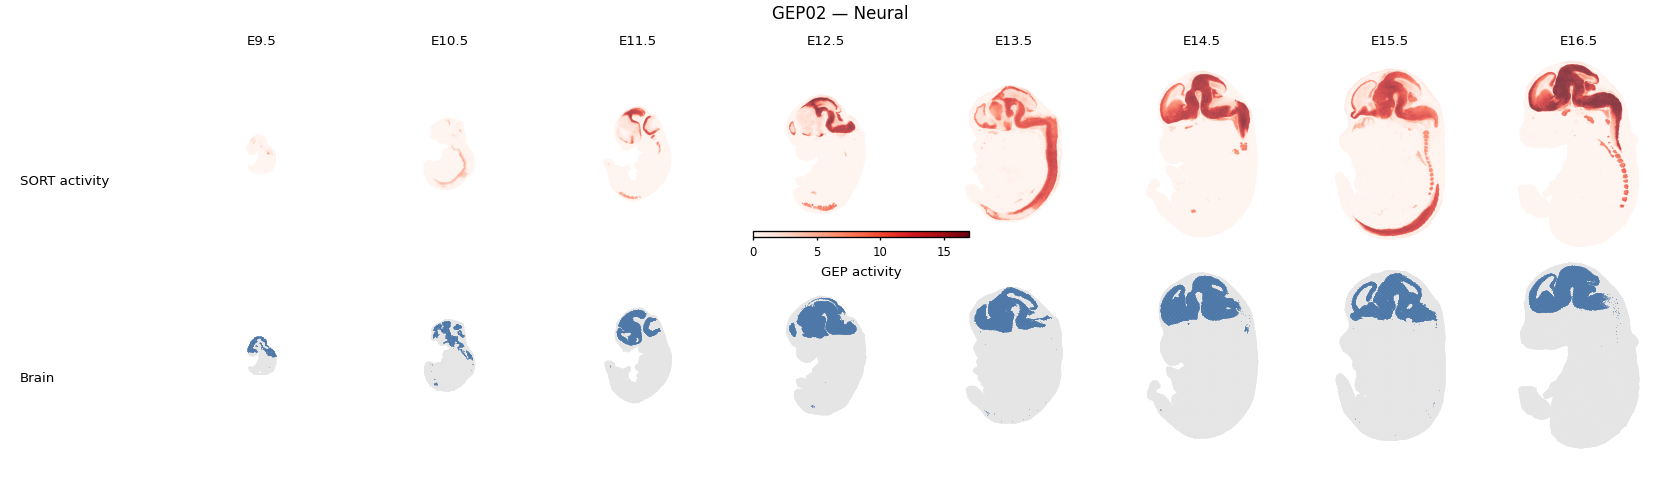

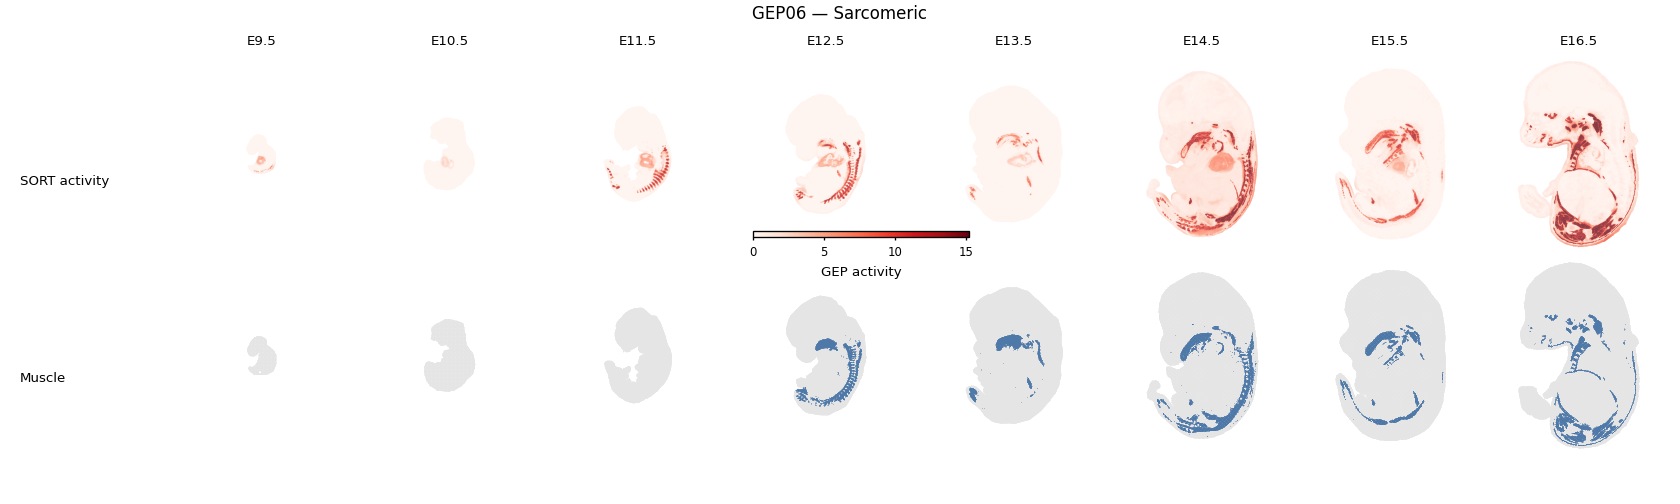

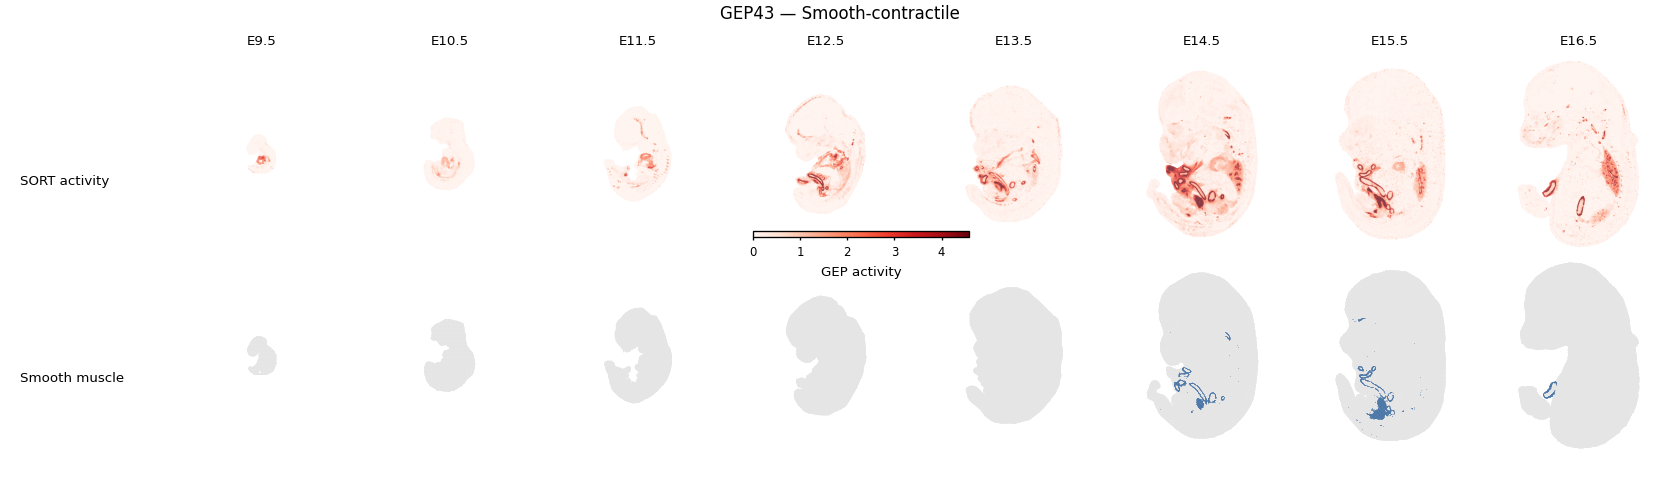

In [12]:
for example in examples:
    plot_program(*example)